In [14]:
import json
import os
import random

import matplotlib.pyplot as plt


In [15]:
class Point:
    def __init__(self, point_id, x, y):
        self.id = point_id
        self.x = x
        self.y = y

    def __repr__(self):
        return f"Point({self.id}, {self.x}, {self.y})"

    def to_dict(self):
        return {"id": self.id, "x": self.x, "y": self.y}

    @classmethod
    def from_dict(cls, data):
        return cls(data["id"], data["x"], data["y"])


In [29]:
class Tour:
    def __init__(self, points):
        self.points = points.copy()

    def generate_random(self):
        random.shuffle(self.points)

    def total_distance(self):
        # sqrt(x² + y²)
        # modulo is for last point to first
        return sum(
            ((self.points[i].x - self.points[(i + 1) % len(self.points)].x)**2 +
             (self.points[i].y - self.points[(i + 1) % len(self.points)].y)**2)**0.5
            for i in range(len(self.points))
        )

    def plot(self, title="Tour"):
        fig, ax = plt.subplots(figsize=(10, 8))

        xs = [p.x for p in self.points] + [self.points[0].x]
        ys = [p.y for p in self.points] + [self.points[0].y]

        ax.plot(xs, ys, marker='o', linestyle='-', color='dodgerblue', markersize=6)
        ax.plot([xs[0]], [ys[0]], marker='s', color='green', markersize=9, label='Start Point')
        ax.legend()
        ax.set_title(title)
        ax.set_xlabel("X Coordinate")
        ax.set_ylabel("Y Coordinate")
        ax.set_xlim(-50, 1050)
        ax.set_ylim(-50, 1050)
        ax.grid(True, linestyle='--', alpha=0.6)
        plt.show()


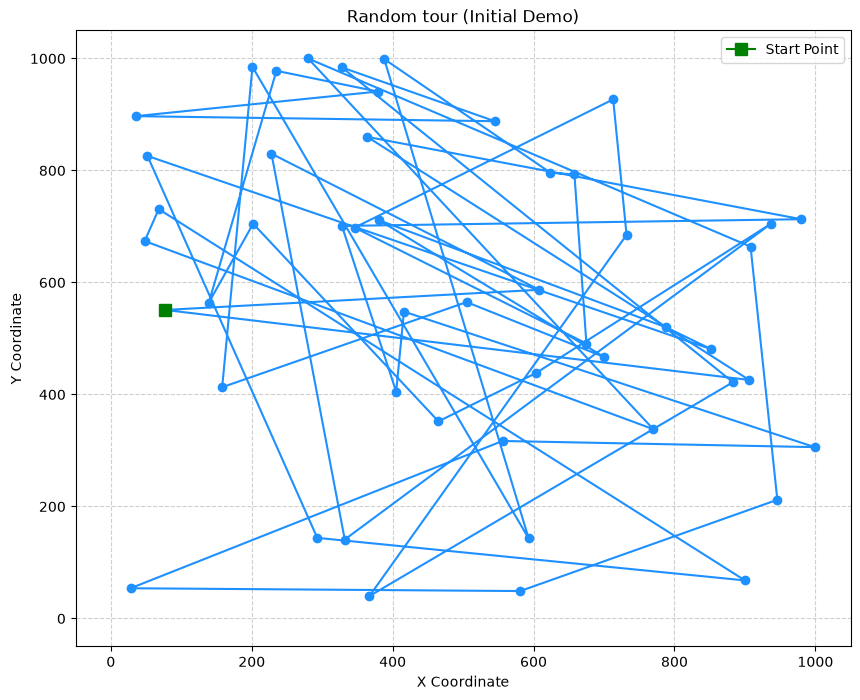

In [30]:
points_list = [Point(i, random.randint(0, 1000), random.randint(0, 1000)) for i in range(50)]

tour = Tour(points_list)
tour.generate_random()
tour.plot(title="Random tour (Initial Demo)")


## 2 Test Dataset


In [18]:
def generate_instances(filename="instances.json", num_instances=10, num_points=50):
    instances = {
        i: [Point(pid, random.randint(0, 1000), random.randint(0, 1000)).to_dict() for pid in range(num_points)]
        for i in range(num_instances)
    }
    with open(filename, "w", encoding="utf-8") as f:
        json.dump(instances, f, indent=2)
    return instances

def load_instances(filename="instances.json"):
    with open(filename, "r", encoding="utf-8") as f:
        data = json.load(f)
    return [[Point.from_dict(p) for p in pts] for pts in data.values()]

def read_dataset(filename="instances.json", instance_id=0):
    return load_instances(filename)[instance_id]

### Generate 10 Different Instances


In [19]:
instances = generate_instances()

## 3. Nearest Neighbour Addition


In [20]:
def nearest_neighbour(points):
    unvisited = points.copy()
    current = unvisited.pop(0)
    tour = [current]
    while unvisited:
        current = min(unvisited, key=lambda p: (current.x - p.x)**2 + (current.y - p.y)**2)
        unvisited.remove(current)
        tour.append(current)
    return tour

def random_tour(points):
    tour = points.copy()
    random.shuffle(tour)
    return tour

def save_tour_to_file(tour, filepath):
    os.makedirs(os.path.dirname(filepath), exist_ok=True)
    with open(filepath, "w", encoding="utf-8") as f:
        f.write(f"{tour.total_distance():.2f}\n\n")
        for p in tour.points:
            f.write(f"{p.id} {float(p.x):.1f} {float(p.y):.1f}\n")

def run_heuristic(heuristic_fn, folder_name):
    folder_path = os.path.join("results", folder_name)
    os.makedirs(folder_path, exist_ok=True)

    results = []
    for idx, points in enumerate(load_instances(), start=1):
        tour = Tour(heuristic_fn(points))
        dist = tour.total_distance()
        save_tour_to_file(tour, os.path.join(folder_path, f"tour_instance_{idx}.txt"))
        results.append((idx, dist, tour))
    return results

def run_heuristic_on_all_instances(heuristic_type="nearest_neighbour"):
    fn = nearest_neighbour if "nearest_neighbour" in heuristic_type else random_tour
    return run_heuristic(fn, heuristic_type)

run_heuristics = run_heuristic


In [21]:
nn_run_results = run_heuristic(nearest_neighbour, "nearest_neighbour")

for idx, dist, _ in nn_run_results:
    print(f"tour_instance_{idx:02d} | Distance={dist:4.0f}")


tour_instance_01 | Distance=7157
tour_instance_02 | Distance=7346
tour_instance_03 | Distance=6420
tour_instance_04 | Distance=7019
tour_instance_05 | Distance=6658
tour_instance_06 | Distance=7143
tour_instance_07 | Distance=7571
tour_instance_08 | Distance=6217
tour_instance_09 | Distance=6942
tour_instance_10 | Distance=7749


In [22]:
random_run_results = run_heuristic(random_tour, "random_tour")

for idx, dist, _ in random_run_results:
    print(f"tour_instance_{idx:02d} | Distance={dist:5.0f}")


tour_instance_01 | Distance=28456
tour_instance_02 | Distance=26950
tour_instance_03 | Distance=24830
tour_instance_04 | Distance=30170
tour_instance_05 | Distance=26159
tour_instance_06 | Distance=27205
tour_instance_07 | Distance=27239
tour_instance_08 | Distance=27679
tour_instance_09 | Distance=26376
tour_instance_10 | Distance=24858


## Result Visualisation


In [23]:
def read_tour_result(filepath):
    with open(filepath, "r", encoding="utf-8") as f:
        lines = [line.strip() for line in f if line.strip()]
    dist = float(lines[0])
    points = [Point(int(p[0]), float(p[1]), float(p[2])) for p in (line.split() for line in lines[1:])]
    return dist, points

def read_all_tour_results(folder_path):
    files = sorted(
        [f for f in os.listdir(folder_path) if f.startswith("tour_instance_")],
        key=lambda f: int(f.split("_")[-1].split(".")[0])
    )
    results = []
    for fn in files:
        iid = int(fn.split("_")[-1].split(".")[0])
        dist, pts = read_tour_result(os.path.join(folder_path, fn))
        results.append({
            "instance_id": iid,
            "filename": fn,
            "distance": dist,
            "points": pts,
            "tour": Tour(pts)
        })
    return results


In [24]:
# read all results
nn_results = read_all_tour_results(os.path.join("results", "nearest_neighbour"))
rnd_results = read_all_tour_results(os.path.join("results", "random_tour"))

nn_dists = [r["distance"] for r in nn_results]
rnd_dists = [r["distance"] for r in rnd_results]


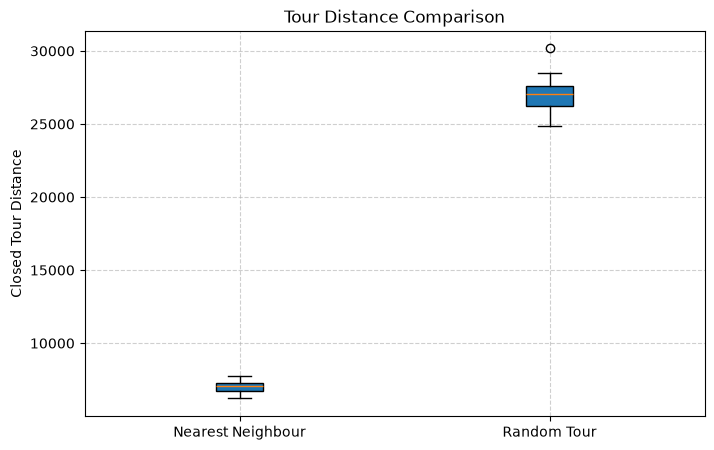

In [25]:

fig, ax = plt.subplots(figsize=(8, 5))
box = ax.boxplot([nn_dists, rnd_dists], tick_labels=["Nearest Neighbour", "Random Tour"], patch_artist=True)


ax.set_title("Tour Distance Comparison")
ax.set_ylabel("Closed Tour Distance")
ax.grid(True, linestyle="--", alpha=0.6)
plt.show()
